In [21]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

print("torch  ", torch.__version__)
print("numpy  ", np.__version__)

# Everything here is CPU-only and deliberately small.
torch.manual_seed(0)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

torch   2.15.0
numpy   2.5.3


In [22]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=400, noise=0.20, random_state=3)
y = y.astype(float)
Y = y.reshape(-1, 1)          # column form, as always

print("X", X.shape, " Y", Y.shape)


def plot_decision_boundary(predict_fn, X, y, title="", ax=None):
    """Shade the plane by what predict_fn says, then scatter the real data on top."""
    if ax is None:
        _, ax = plt.subplots()
    pad = 0.5
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=50, cmap="coolwarm", alpha=0.7)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
    ax.set_title(title)
    return ax

X (400, 2)  Y (400, 1)


In [23]:
# --- the notebook 2 network, condensed ---

def np_init(n_input, n_hidden, seed=0):
    r = np.random.default_rng(seed)
    return {"W1": r.normal(size=(n_input, n_hidden)) * np.sqrt(2.0 / n_input),
            "b1": np.zeros(n_hidden),
            "W2": r.normal(size=(n_hidden, 1)) * np.sqrt(2.0 / n_hidden),
            "b2": np.zeros(1)}


def np_forward(X, p):
    Z1 = X @ p["W1"] + p["b1"]
    A1 = np.maximum(0.0, Z1)
    Z2 = A1 @ p["W2"] + p["b2"]
    A2 = 1.0 / (1.0 + np.exp(-Z2))
    return A2, {"Z1": Z1, "A1": A1, "A2": A2}


def np_backward(X, Y, p, cache):
    n = X.shape[0]
    dZ2 = (cache["A2"] - Y) / n
    dW2 = cache["A1"].T @ dZ2
    db2 = dZ2.sum(axis=0)
    dZ1 = (dZ2 @ p["W2"].T) * (cache["Z1"] > 0)
    return {"W1": X.T @ dZ1, "b1": dZ1.sum(axis=0), "W2": dW2, "b2": db2}


np_params = np_init(2, 16, seed=0)
print("parameter shapes:", {k: v.shape for k, v in np_params.items()})

parameter shapes: {'W1': (2, 16), 'b1': (16,), 'W2': (16, 1), 'b2': (1,)}


---
# 5.1 Tensors

A PyTorch **tensor** is a NumPy array with two extra abilities: it can live on a GPU,
and it can remember how it was computed so that gradients can be traced back through
it. We won't use the GPU at all; the second ability is the whole point of this
notebook.

For everyday use, tensors behave like arrays. The vocabulary carries straight over.

In [24]:
t = torch.tensor([[1.0, 2.0, 3.0],
                 [4.0, 5.0, 6.0]])

print(t)
print("shape ", t.shape)
print("dtype ", t.dtype)
print()
print("t + 10  ->", (t + 10).tolist())
print("t * 2   ->", (t * 2).tolist())
print("t.sum() ->", t.sum().item())
print("t.mean()->", t.mean().item())

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape  torch.Size([2, 3])
dtype  torch.float32

t + 10  -> [[11.0, 12.0, 13.0], [14.0, 15.0, 16.0]]
t * 2   -> [[2.0, 4.0, 6.0], [8.0, 10.0, 12.0]]
t.sum() -> 21.0
t.mean()-> 3.5


In [25]:
arr = np.array([[1.0, 2.0], [3.0, 4.0]])

t_from_np = torch.from_numpy(arr)
back_to_np = t_from_np.numpy()

print("numpy -> tensor", t_from_np.dtype)
print("tensor -> numpy:", type(back_to_np).__name__)

numpy -> tensor torch.float64
tensor -> numpy: ndarray


In [26]:
x = torch.tensor(3.0, requires_grad=True)

f = x ** 2  # Pytorch records: "f came from squaring x"
f.backward()

print("x =", x.item())
print("f =", f.item())
print("x.grad =", x.grad.item())

x = 3.0
f = 9.0
x.grad = 6.0


In [ ]:
np_params = np_init(2, 16, seed=0)

def np_init(n_input, n_hidden, seed=0):
    r = np.random.default_rng(seed)
    return {"W1": r.normal(size=(n_input, n_hidden)) * np.sqrt(2.0 / n_input),
            "b1": np.zeros(n_hidden),
            "W2": r.normal(size=(n_hidden, 1)) * np.sqrt(2.0 / n_hidden),
            "b2": np.zeros(1)}

W1 = torch.tensor(np_params["W1"], requires_grad=True)
b1 = torch.tensor(np_params["b1"], requires_grad=True)
W2 = torch.tensor(np_params["W2"], requires_grad=True)
b2 = torch.tensor(np_params["b2"], requires_grad=True)

X_t = torch.tensor(X)
Y_t = torch.tensor(Y)

print("W1", tuple(W1.shape), W1.dtype, "requires_grad =", W1.requires_grad)
print("X_t", tuple(X_t.shape), X_t.dtype)

W1 (2, 16) torch.float64 requires_grad = True
X_t (400, 2) torch.float64


In [28]:
import torch.nn.functional as F

# ---- forward pass ----
Z1 = X_t @ W1 + b1
A1 = torch.relu(Z1)
Z2 = A1 @ W2 + b2
A2 = torch.sigmoid(Z2)

loss = F.binary_cross_entropy(A2, Y_t)

print("loss = ", loss.item())

# ---- backward pass ----
loss.backward()

loss =  0.7085116545111859


In [29]:
params_list = [W1, b1, W2, b2]
learning_rate = 0.5
losses_v1 = []

for step in range(4000):
    # 1. forward
    A2 = torch.sigmoid(torch.relu(X_t @ W1 + b1) @ W2 + b2)

    # 2. loss
    loss = F.binary_cross_entropy(A2, Y_t)
    losses_v1.append(loss.item())

    # 3. backward
    for p in params_list:
        if p.grad is not None:
            p.grad.zero_()
    loss.backward()

    # 4. update
    with torch.no_grad():
        for p in params_list:
            p -= learning_rate * p.grad

print(f"loss  {losses_v1[0]:.4f}  ->  {losses_v1[-1]:.4f}")

with torch.no_grad():
    preds = torch.sigmoid(torch.relu(X_t @ W1 + b1) @ W2 + b2).numpy().ravel()
print(f"accuracy: {np.mean((preds > 0.5) == y):.1%}")

loss  0.7085  ->  0.0647
accuracy: 97.0%


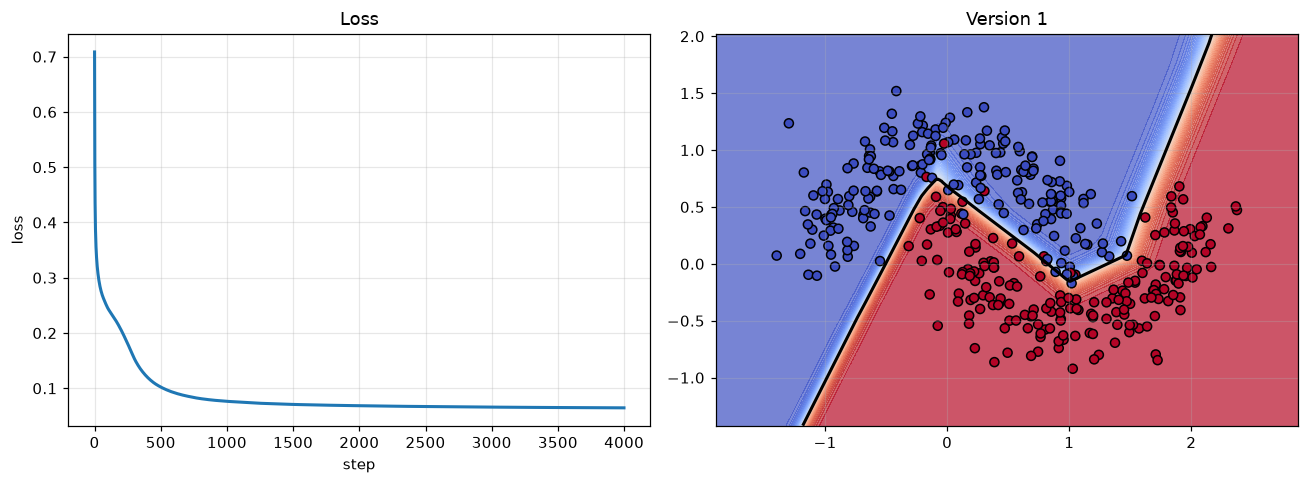

In [32]:
def predict_v1(grid):
    with torch.no_grad():
        g = torch.tensor(grid, dtype=W1.dtype)
        return torch.sigmoid(torch.relu(g @ W1 + b1) @ W2 + b2).numpy().ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(losses_v1, linewidth=2)
axes[0].set_xlabel("step")
axes[0].set_ylabel("loss")
axes[0].set_title("Loss")
plot_decision_boundary(predict_v1, X, y, title="Version 1", ax=axes[1])

plt.tight_layout()
plt.show()

In [33]:
layer = nn.Linear(in_features=2, out_features=16)

print("weight", tuple(layer.weight.shape))
print("bias  ", tuple(layer.bias.shape))
print()
print("both track gradients automatically:", layer.weight.requires_grad)

weight (16, 2)
bias   (16,)

both track gradients automatically: True


In [ ]:
torch.manual_seed(0)

X32 = torch.tensor(X, dtype=torch.float32)
Y32 = torch.tensor(Y, dtype=torch.float32)

lin1 = nn.Linear(2, 16)
lin2 = nn.Linear(16, 1)

params_v2 = list(lin1.parameters()) + list(lin2.parameters())
print("parameter tensors:", [tuple(p.shape) for p in params_v2])

losses_v2 = []
for step in range(4000):
    A2 = torch.sigmoid(lin2(torch.relu(lin1(X32))))  # forward
    loss = F.binary_cross_entropy(A2, Y32)  # loss
    losses_v2.append(loss.item())

    for p in params_v2:
        if p.grad is not None:
            p.grad.zero_()
    loss.backward()  # backward

    with torch.no_grad():
        for p in params_v2:
            p -= 0.5 * p.grad  # update 

with torch.no_grad():
    acc_v2 = (
        (torch.sigmoid(lin2(torch.relu(lin1(X32)))).numpy().ravel() > 0.5) == y
    ).mean()
print(f"loss  {losses_v2[0]:.4f}  ->  {losses_v2[-1]:.4f}   accuracy {acc_v2:.1%}")

parameter tensors: [(16, 2), (16,), (1, 16), (1,)]
loss  0.6792  ->  0.0669   accuracy 97.2%
goodbye
